# Projekt 2: Sieci konwolucyjne i uczenie transferowe w klasyfikacji obrazów

**Zbiór danych:** Galaxy10 DECals, czyli klasyfikacja morfologii galaktyk (10 klas).

**Cel:** porównanie trenowania modelu od podstaw z wykorzystaniem modelu wstępnie wytrenowanego (*pretrained model*).

**Warianty rozwiązania:**
1. Własna sieć konwolucyjna (CNN) trenowana od zera.
2. Model wstępnie wytrenowany z zamrożoną siecią bazową (*backbone*), uczona jest tylko nowa głowica klasyfikacyjna (wydobywanie cech).
3. Ten sam model po częściowym dostrojeniu (*fine-tuning*).

**Eksperyment dodatkowy:** wpływ augmentacji danych albo wielkości zbioru treningowego.

**Metryki:** jakość klasyfikacji, liczba trenowanych parametrów, czas treningu, czas wnioskowania (*inference*).

## 1. Importy


In [1]:
import h5py
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
plt.style.use("default")
plt.rcParams["figure.dpi"] = 72
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms, models
import time
from sklearn.metrics import balanced_accuracy_score
from torch.optim.lr_scheduler import CosineAnnealingLR
from copy import deepcopy
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

## 2.Galaxy10 DECals Dataset

In [2]:
with h5py.File("data/Galaxy10_DECals.h5", "r") as f:
    images = np.array(f["images"])
    labels = np.array(f["ans"])

print(images.shape, labels.shape)
print(np.bincount(labels))

(17736, 256, 256, 3) (17736,)
[1081 1853 2645 2027  334 2043 1829 2628 1423 1873]


## 3. Example Images

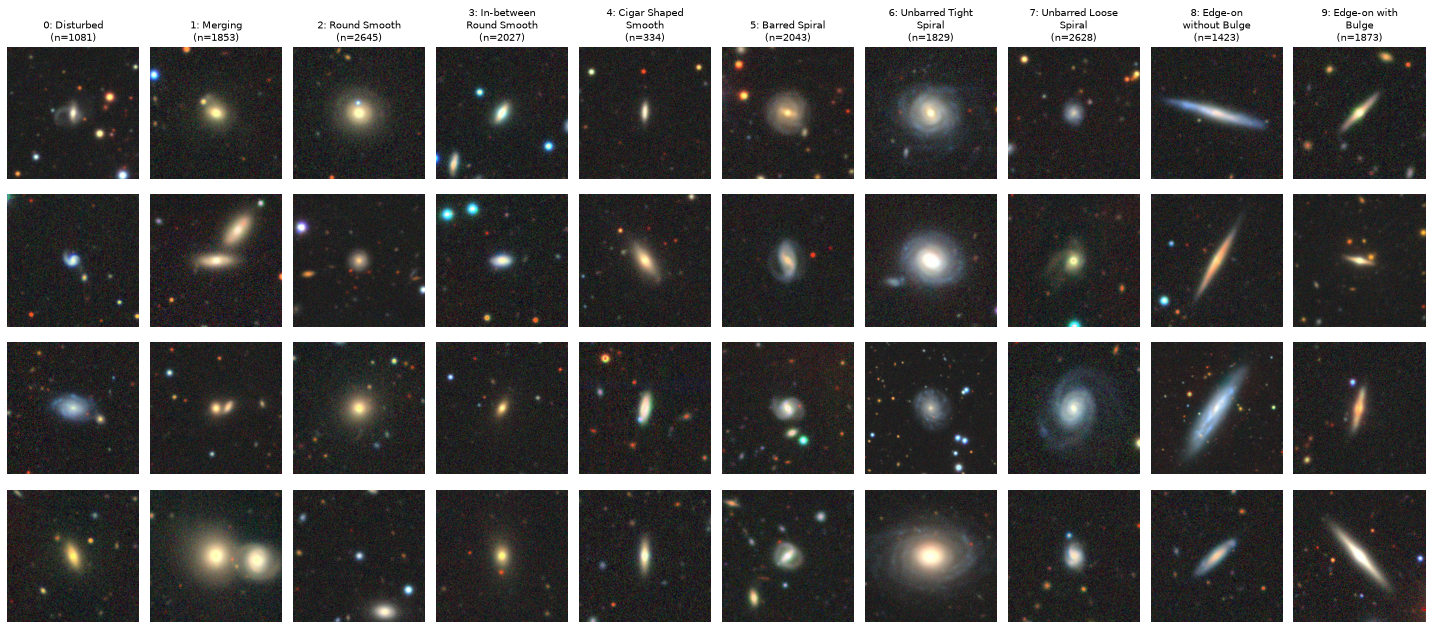

In [3]:
import textwrap

class_names = [
    "Disturbed", "Merging", "Round Smooth", "In-between Round Smooth",
    "Cigar Shaped Smooth", "Barred Spiral", "Unbarred Tight Spiral",
    "Unbarred Loose Spiral", "Edge-on without Bulge", "Edge-on with Bulge",
]

rng = np.random.default_rng(42)
n_per_class = 4
counts = np.bincount(labels)

fig, axes = plt.subplots(n_per_class, len(class_names), figsize=(20, 9))
for cls, name in enumerate(class_names):
    examples = rng.choice(np.where(labels == cls)[0], n_per_class, replace=False)
    for row, i in enumerate(examples):
        axes[row, cls].imshow(images[i])
        axes[row, cls].axis("off")
    axes[0, cls].set_title(f"{cls}: {textwrap.fill(name, 14)}\n(n={counts[cls]})", fontsize=10)

plt.tight_layout()
plt.show()

## 4.Preparing data for PyTorch


In [4]:
class Galaxy10(Dataset):
    def __init__(self,images,labels,indices,transform=None):
        self.images = images
        self.labels = labels
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        j = self.indices[i]
        img = self.images[j]
        if self.transform:
            img = self.transform(img)
        return img, int(self.labels[j])


## 5. Train/Val/Test split and Dataloader


In [5]:
idx = np.arange(len(labels))

train_idx, rest_idx = train_test_split(idx, test_size=0.3,stratify=labels, random_state=42)
val_idx, test_idx = train_test_split(rest_idx, test_size=0.5, stratify=labels[rest_idx], random_state=42)

transform = transforms.Compose([transforms.ToTensor(),
    transforms.Resize((128,128))
])

train_data = Galaxy10(images,labels,train_idx,transform=transform)
val_data = Galaxy10(images,labels,val_idx,transform=transform)
test_data = Galaxy10(images,labels,test_idx,transform=transform)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_data, batch_size=256, shuffle=False)
test_loader  = DataLoader(test_data, batch_size=256, shuffle=False)

x, y = next(iter(train_loader))
print(x.shape, y.shape)

torch.Size([64, 3, 128, 128]) torch.Size([64])


# 6.My own CNN

In [6]:
class smallCNN(nn.Module):

    def __init__(self,n_classes=10):
        self.n_classes = n_classes

        super().__init__()
        self.features = nn.Sequential(
            # (N, 3, 128, 128) -> (N, 32, 128, 128).
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            # (N, 32, 128, 128) -> (N, 32, 64, 64).
            nn.MaxPool2d(kernel_size=2),

            # (N, 32, 64, 64) -> (N, 64, 64, 64).
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            # (N, 64, 64, 64) -> (N, 64, 32, 32).
            nn.MaxPool2d(kernel_size=2),

            # (N, 64, 32, 32) -> (N, 128, 32, 32).
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            # (N, 128, 32, 32) -> (N, 128, 16, 16).
            nn.MaxPool2d(kernel_size=2),

            # (N, 128, 16, 16) -> (N, 256, 16, 16).
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            # (N, 256, 16, 16) -> (N, 256, 8, 8).
            nn.MaxPool2d(kernel_size=2),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            # (N, 256, 1, 1) -> (N, 256).
            nn.Flatten(),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, n_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


# 7.Helper functions


In [14]:
def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def train_one_epoch(model, loader, optimizer, loss_fn, device, frozen_backbone=False, freeze_bn=False,):
    if frozen_backbone:
        model.eval()
        model.fc.train()
    else:
        model.train()

    if freeze_bn:
        for layer in model.modules():
            if isinstance(layer, nn.BatchNorm2d):
                layer.eval()

    total_loss = 0.0
    correct = 0

    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        logits = model(xb)
        loss = loss_fn(logits, yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(xb)

        predictions = logits.detach().argmax(dim=1)
        correct += (predictions == yb).sum().item()

    train_loss = total_loss / len(loader.dataset)
    train_accuracy = correct / len(loader.dataset)

    return train_loss, train_accuracy

def evaluate(model,loader,loss_fn,device):
    model.eval()
    total_loss = 0.0
    correct = 0

    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = loss_fn(logits, yb)
            pred = logits.argmax(dim=1)
            total_loss += loss.item() * len(xb)
            correct += (pred == yb).sum().item()


    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": correct / len(loader.dataset),
    }

def predict(model,loader,device):
    model.eval()
    y_pred = []
    y_true = []
    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb.to(device))
            pred = logits.argmax(dim=1)
            y_pred.extend(pred.cpu().numpy())
            y_true.extend(yb.numpy())

    return y_true, y_pred

# 8.ResNet18 model

In [8]:
def build_resnet_feature_extractor(n_classes):
    weights = models.ResNet18_Weights.DEFAULT
    model = models.resnet18(weights=weights)

    for parameter in model.parameters():
        parameter.requires_grad = False

    n_features = model.fc.in_features
    model.fc = nn.Linear(n_features, n_classes)

    return model, weights.transforms()

# 9.Train CNN

In [9]:

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Urządzenie:", device)

loss_fn = nn.CrossEntropyLoss()
n_epochs = 25
for model_cls in [smallCNN]:
    model = model_cls().to(device)
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-3)
    scheduler = CosineAnnealingLR(optimizer, T_max=n_epochs)

    best_val_loss = float("inf")
    best_state = None

    start = time.perf_counter()
    for epoch in range(n_epochs):
        train_loss = train_one_epoch(model,train_loader,optimizer,loss_fn,device)
        val_result = evaluate(model,val_loader,loss_fn,device)
        scheduler.step()
        print(model_cls.__name__, epoch + 1, train_loss, val_result)

        if val_result["loss"] < best_val_loss:
            best_val_loss = val_result["loss"]
            best_state = deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    elapsed = time.perf_counter() - start
    print("Parameters:", count_parameters(model))
    print("Learning time:", elapsed)
    torch.save(model.state_dict(), results_dir / "smallCNN.pt")

print("Test:", evaluate(model, test_loader, loss_fn, device))

Urządzenie: mps
smallCNN 1 1.927302524239797 {'loss': 1.7895961230858823, 'accuracy': 0.32669172932330826}
smallCNN 2 1.6788077244295787 {'loss': 1.5333193890134196, 'accuracy': 0.41616541353383457}
smallCNN 3 1.5060490700394888 {'loss': 1.7875501229350728, 'accuracy': 0.3462406015037594}
smallCNN 4 1.3822567069141605 {'loss': 1.4406025262703572, 'accuracy': 0.46616541353383456}
smallCNN 5 1.2988437928070333 {'loss': 1.498547467253262, 'accuracy': 0.4120300751879699}
smallCNN 6 1.2143178046445813 {'loss': 1.8574604733545976, 'accuracy': 0.37330827067669176}
smallCNN 7 1.167865039742478 {'loss': 1.1128201823485524, 'accuracy': 0.5969924812030075}
smallCNN 8 1.117438375023263 {'loss': 1.2025681553030372, 'accuracy': 0.5733082706766918}
smallCNN 9 1.0557446173588403 {'loss': 1.3278060667496874, 'accuracy': 0.5180451127819549}
smallCNN 10 1.0201709755140114 {'loss': 1.125200951547551, 'accuracy': 0.6011278195488722}
smallCNN 11 0.9596753816666067 {'loss': 0.9799793092828047, 'accuracy': 0.

# 10.Confiuson Matrix for my CNN

Balanced accuracy: 0.6969112916551243


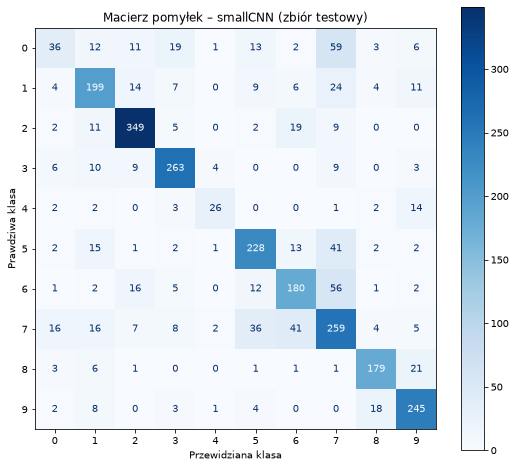

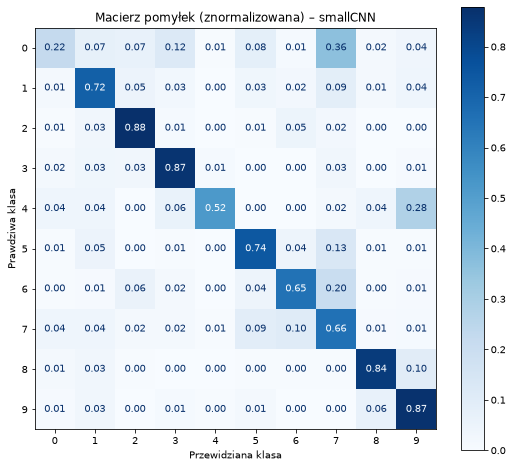

In [10]:
y_true, y_pred = predict(model, test_loader, device)
print("Balanced accuracy:", balanced_accuracy_score(y_true, y_pred))

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, cmap="Blues", ax=ax)
ax.set_xlabel("Przewidziana klasa")
ax.set_ylabel("Prawdziwa klasa")
ax.set_title("Macierz pomyłek – smallCNN (zbiór testowy)")
fig.savefig(results_dir / "confusion_matrix_smallCNN.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, normalize="true",
                                        values_format=".2f", cmap="Blues", ax=ax)
ax.set_xlabel("Przewidziana klasa")
ax.set_ylabel("Prawdziwa klasa")
ax.set_title("Macierz pomyłek (znormalizowana) – smallCNN")
fig.savefig(results_dir / "confusion_matrix_smallCNN_normalized.png", dpi=150, bbox_inches="tight")
plt.show()

# 11.ResNet18 data preparing

In [11]:
resnet_model, resnet_preprocess = build_resnet_feature_extractor(n_classes=10)
resnet_model = resnet_model.to(device)

resnet_transform = transforms.Compose([
    transforms.ToTensor(),
    resnet_preprocess,
])

resnet_train_data = Galaxy10(images, labels, train_idx, transform=resnet_transform)
resnet_val_data = Galaxy10(images, labels, val_idx, transform=resnet_transform)
resnet_test_data = Galaxy10(images, labels, test_idx, transform=resnet_transform)
resnet_train_loader = DataLoader(resnet_train_data, batch_size=64, shuffle=True)
resnet_val_loader = DataLoader(resnet_val_data, batch_size=64, shuffle=False)
resnet_test_loader = DataLoader(resnet_test_data, batch_size=64, shuffle=False)

optimizer = torch.optim.Adam(resnet_model.fc.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

1.7%

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/bartekszkola/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100.0%


# 12.Train ResNet18 head

In [12]:
n_epochs = 10

best_resnet_val_loss = float("inf")
best_resnet_state = None

start = time.perf_counter()

for epoch in range(n_epochs):
    train_loss = train_one_epoch(resnet_model, resnet_train_loader,
                                 optimizer,loss_fn,device,frozen_backbone=True)

    val_result = evaluate(resnet_model, resnet_val_loader, loss_fn, device)
    print("ResNet18", epoch + 1, train_loss, val_result)

    if val_result["loss"] < best_resnet_val_loss:
        best_resnet_val_loss = val_result["loss"]
        best_resnet_state = deepcopy(resnet_model.state_dict())

resnet_training_time = time.perf_counter() - start
resnet_model.load_state_dict(best_resnet_state)
print("Parameters:", count_parameters(resnet_model))
print("Learning time:", resnet_training_time)
print("Test result:", evaluate(resnet_model, resnet_test_loader, loss_fn, device))
torch.save(resnet_model.state_dict(), results_dir / "resnet18_frozen_backbone.pt")

ResNet18 1 1.7087321184740594 {'loss': 1.4865792995108698, 'accuracy': 0.47330827067669173}
ResNet18 2 1.459356291247048 {'loss': 1.3875312794420056, 'accuracy': 0.5165413533834586}
ResNet18 3 1.3835348077997582 {'loss': 1.3279939848677556, 'accuracy': 0.5300751879699248}
ResNet18 4 1.3379364572510428 {'loss': 1.3030241159568157, 'accuracy': 0.5319548872180451}
ResNet18 5 1.3011063074902378 {'loss': 1.2755182542298968, 'accuracy': 0.5338345864661654}
ResNet18 6 1.2777190626315709 {'loss': 1.2666651037402619, 'accuracy': 0.5511278195488721}
ResNet18 7 1.2558148274342955 {'loss': 1.2511160981386227, 'accuracy': 0.5518796992481203}
ResNet18 8 1.244312295959786 {'loss': 1.2517670995310732, 'accuracy': 0.5409774436090226}
ResNet18 9 1.2288063684875237 {'loss': 1.2275926181248256, 'accuracy': 0.5575187969924812}
ResNet18 10 1.2141263900146915 {'loss': 1.219018901201119, 'accuracy': 0.5601503759398496}
Parameters: (11181642, 5130)
Learning time: 396.75286404113285
Test result: {'loss': 1.2634

# 13.Confiusion Matrix for ResNet18 head

Balanced accuracy: 0.5152091726890276


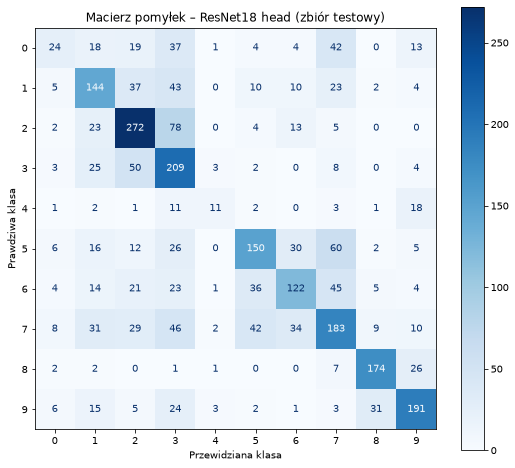

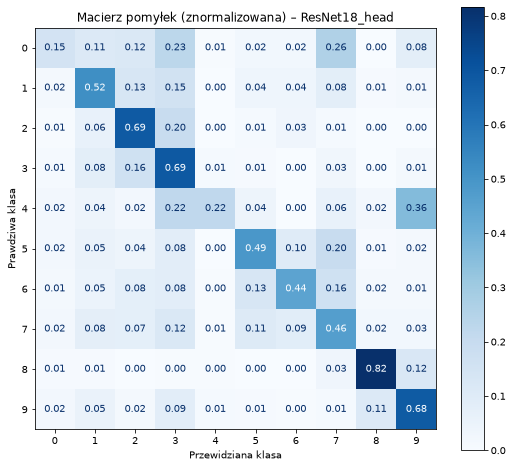

In [13]:
y_true_resnet, y_pred_resnet = predict(resnet_model, resnet_test_loader, device)
print("Balanced accuracy:", balanced_accuracy_score(y_true_resnet, y_pred_resnet))

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_true_resnet, y_pred_resnet, cmap="Blues", ax=ax)
ax.set_xlabel("Przewidziana klasa")
ax.set_ylabel("Prawdziwa klasa")
ax.set_title("Macierz pomyłek – ResNet18 head (zbiór testowy)")
fig.savefig(results_dir / "confusion_matrix_ResNet18_head.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_true_resnet, y_pred_resnet, normalize="true",
                                        values_format=".2f", cmap="Blues", ax=ax)
ax.set_xlabel("Przewidziana klasa")
ax.set_ylabel("Prawdziwa klasa")
ax.set_title("Macierz pomyłek (znormalizowana) – ResNet18_head")
fig.savefig(results_dir / "confusion_matrix_ResNet18_head_normalized.png", dpi=150, bbox_inches="tight")
plt.show()

# 14. ResNet18 fine-tuning

In [15]:
resnet_ft_model = deepcopy(resnet_model)

for parameter in resnet_ft_model.parameters():
    parameter.requires_grad = False

for parameter in resnet_ft_model.layer4.parameters():
    parameter.requires_grad = True

for parameter in resnet_ft_model.fc.parameters():
    parameter.requires_grad = True

ft_optimizer = torch.optim.Adam([
    {"params": resnet_ft_model.layer4.parameters(), "lr": 1e-5},
    {"params": resnet_ft_model.fc.parameters(), "lr": 1e-4},
])

print("Parameters:", count_parameters(resnet_ft_model))

Parameters: (11181642, 8398858)


In [16]:
ft_epochs = 15
best_ft_val_loss = float("inf")
best_ft_state = None

start = time.perf_counter()

for epoch in range(ft_epochs):
    train_loss = train_one_epoch(resnet_ft_model,resnet_train_loader, ft_optimizer, loss_fn, device, freeze_bn=True)
    val_result = evaluate(resnet_ft_model, resnet_val_loader, loss_fn, device)

    print("ResNet18 fine-tuning", epoch + 1, train_loss, val_result)

    if val_result["loss"] < best_ft_val_loss:
        best_ft_val_loss = val_result["loss"]
        best_ft_state = deepcopy(resnet_ft_model.state_dict())

ft_training_time = time.perf_counter() - start
resnet_ft_model.load_state_dict(best_ft_state)

print("Learning time:", ft_training_time)
print("Test result:", evaluate(resnet_ft_model, resnet_test_loader, loss_fn, device))

torch.save(resnet_ft_model.state_dict(), results_dir / "resnet18_finetuned.pt")

ResNet18 fine-tuning 1 1.117154968677871 {'loss': 1.0861871532927778, 'accuracy': 0.6112781954887218}
ResNet18 fine-tuning 2 0.9664910540146737 {'loss': 0.9897777064402301, 'accuracy': 0.6526315789473685}
ResNet18 fine-tuning 3 0.8688425606794046 {'loss': 0.9583169965815723, 'accuracy': 0.6560150375939849}
ResNet18 fine-tuning 4 0.795041338834751 {'loss': 0.9490411601568524, 'accuracy': 0.674436090225564}
ResNet18 fine-tuning 5 0.7230107204692287 {'loss': 0.9252884459674806, 'accuracy': 0.6789473684210526}
ResNet18 fine-tuning 6 0.6653171186239739 {'loss': 0.9014797408777968, 'accuracy': 0.687593984962406}
ResNet18 fine-tuning 7 0.6023244836519573 {'loss': 0.8952242512451974, 'accuracy': 0.693609022556391}
ResNet18 fine-tuning 8 0.5489326444115794 {'loss': 0.9472921401934516, 'accuracy': 0.6740601503759398}
ResNet18 fine-tuning 9 0.5001195333366955 {'loss': 0.9013807213396058, 'accuracy': 0.6977443609022557}
ResNet18 fine-tuning 10 0.449353224502376 {'loss': 0.9399116197026762, 'accura

# 15. Confiusion matrix ResNet18 ft

Balanced accuracy: 0.6424772848533575


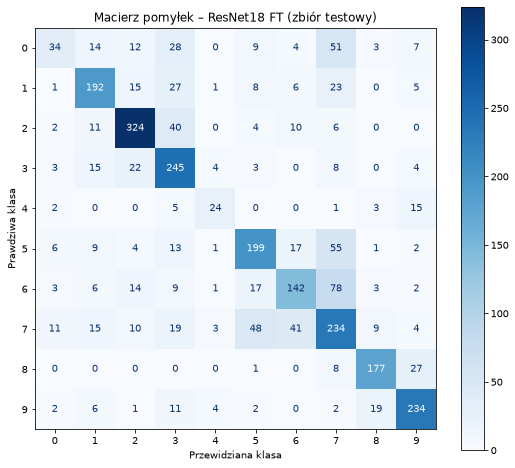

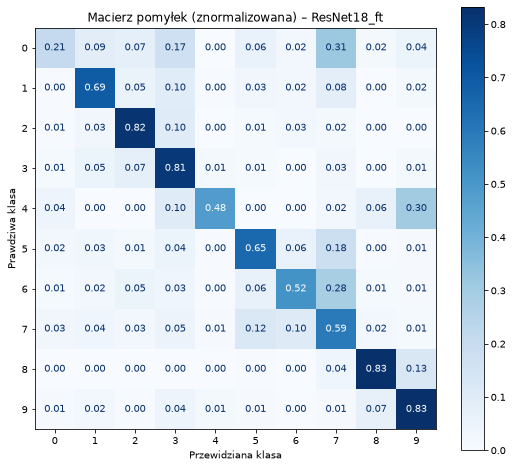

In [17]:
y_true_ft, y_pred_ft = predict(resnet_ft_model, resnet_test_loader, device)
print("Balanced accuracy:", balanced_accuracy_score(y_true_ft, y_pred_ft))

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_true_ft, y_pred_ft, cmap="Blues", ax=ax)
ax.set_xlabel("Przewidziana klasa")
ax.set_ylabel("Prawdziwa klasa")
ax.set_title("Macierz pomyłek – ResNet18 FT (zbiór testowy)")
fig.savefig(results_dir / "confusion_matrix_ResNet18_ft.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_true_ft, y_pred_ft, normalize="true",
                                        values_format=".2f", cmap="Blues", ax=ax)
ax.set_xlabel("Przewidziana klasa")
ax.set_ylabel("Prawdziwa klasa")
ax.set_title("Macierz pomyłek (znormalizowana) – ResNet18_ft")
fig.savefig(results_dir / "confusion_matrix_ResNet18_ft_normalized.png", dpi=150, bbox_inches="tight")
plt.show()

# 16. My own CNN + aug

In [18]:
cnn_aug_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
])

cnn_aug_train_data = Galaxy10(images, labels, train_idx, transform=cnn_aug_transform)
cnn_aug_train_loader = DataLoader(cnn_aug_train_data, batch_size=64, shuffle=True)

cnn_aug_model = smallCNN().to(device)

cnn_aug_optimizer = torch.optim.Adam(cnn_aug_model.parameters(), lr=1e-3)

cnn_aug_epochs = 25

cnn_aug_scheduler = CosineAnnealingLR(cnn_aug_optimizer, T_max=cnn_aug_epochs)

loss_fn = nn.CrossEntropyLoss()
best_cnn_aug_val_loss = float("inf")
best_cnn_aug_state = None

start = time.perf_counter()

for epoch in range(cnn_aug_epochs):
    train_loss = train_one_epoch(cnn_aug_model, cnn_aug_train_loader, cnn_aug_optimizer, loss_fn, device)
    val_result = evaluate(cnn_aug_model, val_loader, loss_fn, device)
    cnn_aug_scheduler.step()
    print("smallCNN augmentation", epoch + 1, train_loss, val_result)

    if val_result["loss"] < best_cnn_aug_val_loss:
        best_cnn_aug_val_loss = val_result["loss"]
        best_cnn_aug_state = deepcopy(cnn_aug_model.state_dict())

cnn_aug_model.load_state_dict(best_cnn_aug_state)
cnn_aug_training_time = time.perf_counter() - start

print("Parameters:", count_parameters(cnn_aug_model))
print("Learning time:", cnn_aug_training_time)
print("Test result:", evaluate(cnn_aug_model, test_loader, loss_fn, device))

torch.save(cnn_aug_model.state_dict(), results_dir / "smallCNN_aug.pt")

smallCNN augmentation 1 1.9005272717232 {'loss': 2.0683974151324507, 'accuracy': 0.26654135338345863}
smallCNN augmentation 2 1.6317316652832614 {'loss': 1.6092497850719252, 'accuracy': 0.381203007518797}
smallCNN augmentation 3 1.4726991903095346 {'loss': 1.905425348855499, 'accuracy': 0.34962406015037595}
smallCNN augmentation 4 1.3607365648831948 {'loss': 1.4563195603234427, 'accuracy': 0.4567669172932331}
smallCNN augmentation 5 1.2780462718806918 {'loss': 1.3654318320123773, 'accuracy': 0.4917293233082707}
smallCNN augmentation 6 1.2057590338476136 {'loss': 1.1180287527858763, 'accuracy': 0.5992481203007519}
smallCNN augmentation 7 1.142700609563581 {'loss': 1.1741844114504363, 'accuracy': 0.5808270676691729}
smallCNN augmentation 8 1.0899821646790613 {'loss': 1.1182406678235621, 'accuracy': 0.5887218045112782}
smallCNN augmentation 9 1.0382279187884966 {'loss': 1.0691495284102017, 'accuracy': 0.6172932330827068}
smallCNN augmentation 10 1.0008605796101109 {'loss': 0.9390833583989

# 17. Confusion Matrix CNN Augmentation

In [ ]:
y_true_aug, y_pred_aug = predict(cnn_aug_model, test_loader, device)
print("Balanced accuracy:", balanced_accuracy_score(y_true_aug, y_pred_aug))

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_true_aug, y_pred_aug, cmap="Blues", ax=ax)
ax.set_xlabel("Przewidziana klasa")
ax.set_ylabel("Prawdziwa klasa")
ax.set_title("Macierz pomyłek – smallCNN AUG (zbiór testowy)")
fig.savefig(results_dir / "confusion_matrix_smallCNN_aug.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_true_aug, y_pred_aug, normalize="true",
                                        values_format=".2f", cmap="Blues", ax=ax)
ax.set_xlabel("Przewidziana klasa")
ax.set_ylabel("Prawdziwa klasa")
ax.set_title("Macierz pomyłek (znormalizowana) – smallCNN AUG")
fig.savefig(results_dir / "confusion_matrix_smallCNN_aug_normalized.png", dpi=150, bbox_inches="tight")
plt.show()